# Báo cáo tiến độ

In [ ]:
# Multi-Model Training and Evaluation Pipeline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import os
import tensorflow as tf
from sklearn.preprocessing import OrdinalEncoder
import lightgbm as lgb
import xgboost as xgb
import catboost as cb
from sklearn.ensemble import RandomForestRegressor, VotingRegressor
import os, sys, gc, time, warnings, pickle, psutil, random
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error
import math
from lightgbm import early_stopping, log_evaluation
import tracemalloc

print("Num GPUs Available:", len(tf.config.experimental.list_physical_devices('GPU')))
print("GPU Details:", tf.config.experimental.list_physical_devices('GPU'))

# Load and prepare data (keeping your original preprocessing)
df = pd.read_parquet('/kaggle/input/data-cs116/train_val.parquet')
print(df.columns)
print(df['disaster_severity_flag'].unique())
df = df.drop(['date','disaster_type'],axis=1)

def downcast(df):
    cols = df.dtypes.index.tolist()
    types = df.dtypes.values.tolist()
   
    for i, t in enumerate(types):
        col = cols[i]
        if 'int' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                df[col] = df[col].astype(np.int8)
            elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                df[col] = df[col].astype(np.int16)
            elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                df[col] = df[col].astype(np.int32)
            else:
                df[col] = df[col].astype(np.int64)
        elif 'float' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            if c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                df[col] = df[col].astype(np.float32)
            else:
                df[col] = df[col].astype(np.float64)    
    return df

sample_submission = pd.read_csv('/kaggle/input/data-cs116/submission.csv')
sample_submission = downcast(sample_submission)

# Constants
LAGS = [7, 28]
WINDOWS = [7, 28]
FIRST = 1942
LENGTH = 28

def demand_features_eval(df):
    """ Same as demand_features but for the step-by-step evaluation """
    out = df.groupby('id', sort=False).last()
    for lag in LAGS:
        out[f'lag_t{lag}'] = df.groupby('id', sort=False)['demand'].nth(-lag-1).astype("float32")
        for w in WINDOWS:
            out[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id', sort=False)['demand'].nth(list(range(-lag-w, -lag))).groupby('id', sort=False).mean().astype("float32")
   
    return out.reset_index()

def prep_train(df, drop_d=1000):
    x = list(set(df.columns) - {'id', 'd', 'demand'})
    print(f"Features: {x}")
    
    # Split into test, valid, train
    test = df[df.d >= FIRST - max(LAGS) - max(WINDOWS) - 28]
    df = df[df.d < FIRST]
    xtrain, xvalid, ytrain, yvalid = train_test_split(df[x], df["demand"], test_size=0.1, shuffle=True, random_state=54)
    
    return xtrain, xvalid, ytrain, yvalid, test, x

# Metric calculation functions
def calculate_mape(y_true, y_pred):
    """Calculate Mean Absolute Percentage Error"""
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    # Avoid division by zero
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

def calculate_metrics(y_true, y_pred):
    """Calculate all metrics"""
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    mape = calculate_mape(y_true, y_pred)
    return {'MAE': mae, 'MSE': mse, 'MAPE': mape}

def get_memory_usage():
    """Get current memory usage in MB"""
    process = psutil.Process(os.getpid())
    return process.memory_info().rss / 1024 / 1024

from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import time
import psutil
import gc

def evaluate_model(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred)
    mem = psutil.Process().memory_info().rss / 1024**2  # MB
    print(f"{name:<15} | MAE: {mae:.4f} | MSE: {mse:.4f} | MAPE: {mape:.4f} | Memory: {mem:.2f} MB")
    return {'Model': name, 'MAE': mae, 'MSE': mse, 'MAPE': mape, 'Memory_MB': mem}

Num GPUs Available: 1
GPU Details: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Do có nhiều sự lựa chọn nên ở đây tụi em quyết định chọn LightGBM do có hiệu năng và cũng là model mạnh nhất hiện tại

Sau nhiều lần thử nghiệm với các model khác thì thấy LightGBM hiệu suất hơn hẳn

# Tối ưu trọng số bằng Bayesian optimization

  Để tối ưu trọng số, nhóm đã sử dụng tối ưu trọng số bằng thuật toán Tree-structured Parzen Estimator thuộc phương pháp bayesian optimization.


### 📌 TPE là gì?

TPE (Tree-structured Parzen Estimator) là một thuật toán tối ưu hóa Bayes, dùng để chọn ra các siêu tham số tốt nhất bằng cách mô hình hóa xác suất của tham số dựa trên kết quả trước đó. Thay vì tìm giá trị nào tối ưu hóa hàm mất mát, TPE ước lượng phân phối xác suất và lấy mẫu thông minh từ đó để tìm ra tổ hợp tốt hơn qua từng vòng lặp.

---

### 🔍 Nguyên lý hoạt động

TPE không xây dựng mô hình trực tiếp cho `objective function`, mà nó **mô hình hóa xác suất ngược**:

$$[
P(x | y) \quad \text{thay vì} \quad P(y | x)
]$$

TPE chia kết quả các trial thành hai nhóm:
- **Good trials**: Những bộ tham số có điểm số tốt nhất (ví dụ, loss thấp nhất).
- **Bad trials**: Phần còn lại.

Sau đó, TPE:
- Ước lượng hai phân phối xác suất: $$( l(x) )$$ và $$( g(x) )$$
  - $$( l(x) = P(x | y < y^*) )$$
  - $$( g(x) = P(x | y \geq y^*) )$$
- Chọn tham số mới $$( x )$$ sao cho **tỉ lệ** $$( \frac{l(x)}{g(x)} )$$ là **cao nhất**.

---

### 📈 Ưu điểm

- Khả năng học từ lịch sử trial để cải thiện dần dần.
- Tốt hơn random search đặc biệt trong không gian tham số liên tục hoặc rộng.
- Hỗ trợ các loại siêu tham số: `int`, `float`, `categorical`, `log-uniform`, v.v.

---


# Lựa chọn model

Sau khi chạy toàn bộ cặp (Model và độ đo) với tập train, nhóm rút ra bảng số liệu bằng cách chấm trên cùng 1 tập validation như sau:
         
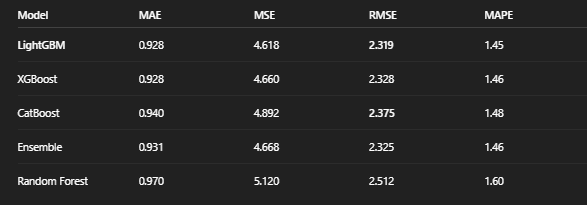

In [ ]:
import lightgbm as lgb

def train_lgbm(xtrain, ytrain, xvalid, yvalid):
    params = {
        'objective': 'regression',
        'metric': 'rmse',
        'device': 'gpu',
        'gpu_platform_id': 0,
        'gpu_device_id': 0,
        'max_bin': 255,
        'learning_rate': 0.05,
        'verbosity': -1
    }
    train_data = lgb.Dataset(xtrain, label=ytrain)
    valid_data = lgb.Dataset(xvalid, label=yvalid)
    start = time.time()
    model = lgb.train(params, train_data, valid_sets=[valid_data], num_boost_round=800, 
                     callbacks=[early_stopping(50), log_evaluation(100)])
    duration = time.time() - start
    y_pred = model.predict(xvalid)
    metrics = evaluate_model("LightGBM", yvalid, y_pred)
    metrics['Time_sec'] = duration
    return model, metrics

import xgboost as xgb

def train_xgb(xtrain, ytrain, xvalid, yvalid):
    params = {
        'tree_method': 'gpu_hist',
        'gpu_id': 0,
        # 'predictor': 'gpu_predictor',
        'objective': 'reg:squarederror',
        'eval_metric': 'rmse',
        'learning_rate': 0.05,
        'max_depth': 6,
    }
    dtrain = xgb.DMatrix(xtrain, label=ytrain)
    dvalid = xgb.DMatrix(xvalid, label=yvalid)
    start = time.time()
    model = xgb.train(params, dtrain, num_boost_round=800, evals=[(dvalid, 'valid')],
                      early_stopping_rounds=50, verbose_eval=100)
    duration = time.time() - start
    y_pred = model.predict(xgb.DMatrix(xvalid))
    metrics = evaluate_model("XGBoost", yvalid, y_pred)
    metrics['Time_sec'] = duration
    return model, metrics

from catboost import CatBoostRegressor

def train_catboost(xtrain, ytrain, xvalid, yvalid):
    model = CatBoostRegressor(
        iterations=800,
        learning_rate=0.05,
        depth=6,
        loss_function='RMSE',
        task_type='GPU',
        devices='0',
        verbose=100
    )
    start = time.time()
    model.fit(xtrain, ytrain, eval_set=(xvalid, yvalid), early_stopping_rounds=50, use_best_model=True)
    duration = time.time() - start
    y_pred = model.predict(xvalid)
    metrics = evaluate_model("CatBoost", yvalid, y_pred)
    metrics['Time_sec'] = duration
    return model, metrics
from sklearn.ensemble import RandomForestRegressor

def train_rf(xtrain, ytrain, xvalid, yvalid):
    model = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)
    start = time.time()
    model.fit(xtrain, ytrain)
    duration = time.time() - start
    y_pred = model.predict(xvalid)
    metrics = evaluate_model("RandomForest", yvalid, y_pred)
    metrics['Time_sec'] = duration
    return model, metrics

def ensemble_predict(models, xvalid):
    preds = []
    for model in models:
        if 'xgb' in str(type(model)).lower():
            dmatrix = xgb.DMatrix(xvalid)
            preds.append(model.predict(dmatrix))
        else:
            preds.append(model.predict(xvalid))
    y_pred = np.mean(preds, axis=0)
    return y_pred


In [ ]:
from sklearn.impute import SimpleImputer

# Prepare data
xtrain, xvalid, ytrain, yvalid, test, x = prep_train(df, 1000 - 28)

# Impute NaN trước khi train
imputer = SimpleImputer(strategy='mean')
xtrain = pd.DataFrame(imputer.fit_transform(xtrain), columns=xtrain.columns)
xvalid = pd.DataFrame(imputer.transform(xvalid), columns=xvalid.columns)
del df
gc.collect()

results = []

# Huấn luyện
lgb_model, lgb_metrics = train_lgbm(xtrain, ytrain, xvalid, yvalid); gc.collect()
xgb_model, xgb_metrics = train_xgb(xtrain, ytrain, xvalid, yvalid); gc.collect()
cat_model, cat_metrics = train_catboost(xtrain, ytrain, xvalid, yvalid); gc.collect()
rf_model, rf_metrics = train_rf(xtrain, ytrain, xvalid, yvalid); gc.collect()

# Gộp kết quả
results.extend([lgb_metrics, xgb_metrics, cat_metrics])

In [ ]:
# Ensemble
ensemble_y_pred = ensemble_predict([lgb_model, xgb_model, cat_model], xvalid)
ensemble_metrics = evaluate_model("Ensemble", yvalid, ensemble_y_pred)
ensemble_metrics['Time_sec'] = "-"
results.append(ensemble_metrics)

# Xuất DataFrame
results_df = pd.DataFrame(results)
print("\n📊 Tổng kết:")
print(results_df)

Thông qua bảng trên, mình nhận thấy lightGBM đạt score tốt nhất trong tất cả các cột. Vì thế nhóm đã kết luận sử dụng lightGBM và nộp vào cuộc thi, đạt được score 0.58 (rank 64)

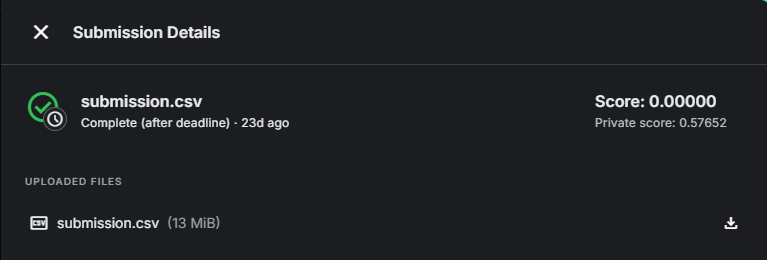
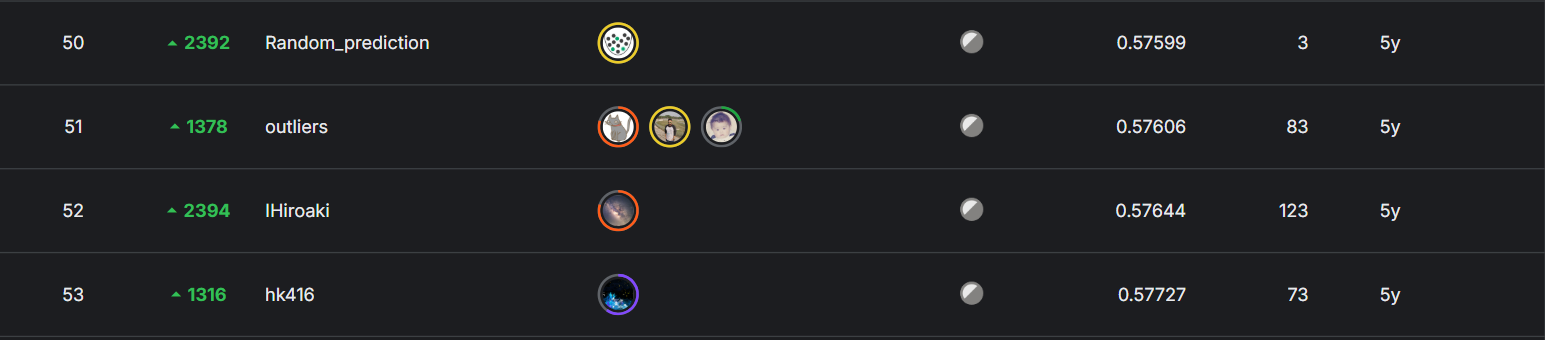